1)	Train a binary classifier SGD according to the instructions in the course book with one important exception: Select one digit, but not the digit 5.

In [1]:
import sys
assert sys.version_info >= (3, 7)

from packaging import version
import numpy as np
import sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [2]:
mnist = fetch_openml('mnist_784', as_frame = False)
X, y = mnist['data'], mnist['target']

#Splitting train and test sets
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

C:\Users\Henna\anaconda3\Lib\site-packages\sklearn\datasets\_openml.py:968: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [3]:
#Creating a 7-detector
y_train_7 = (y_train== '7')
y_test_7 = (y_test == '7')

#Training a binary class
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_7)


SGDClassifier(random_state=42)

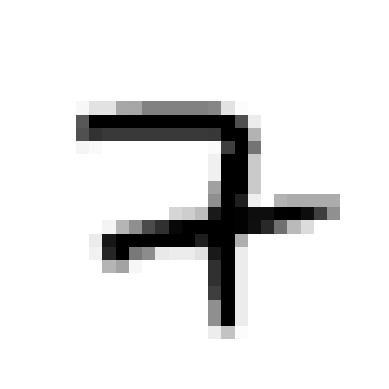

array([ True])

In [4]:
import matplotlib.pyplot as plt
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")
some_digit = X[38]
plot_digit(some_digit)
plt.show()

#can detect imags of the number 7
sgd_clf.predict([some_digit])

2)	Use 7-fold cross-validation. Continue with the digit you selected in task 1. What are the minimum and maximum accuracies you get? 

In [5]:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf, X_train, y_train_7, cv=7, scoring="accuracy")

array([0.97888474, 0.9829678 , 0.96686888, 0.97946564, 0.97479874,
       0.96581496, 0.98109905])

Min accuracy = 0,966 and max accuracy = 0,978

In [6]:
#Testing also models accuracy with dummy classifier
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_7)
cross_val_score(dummy_clf, X_train, y_train_7, cv=7, scoring="accuracy")

array([0.89559029, 0.89559029, 0.89559029, 0.89557811, 0.89557811,
       0.89557811, 0.89557811])

3)	Calculate the confusion matrix, and then, precision, recall and F1 measures. Continue with the digit you selected in task 1. 

In [7]:
#First make set of predictions
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_7, cv=5)

#Make confusion matrix with y_train_pred

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_7, y_train_pred)
cm

array([[53180,   555],
       [  768,  5497]], dtype=int64)

In [8]:
#Calculate precision score 
from sklearn.metrics import precision_score
precision_score(y_train_7, y_train_pred)

0.9082947785855915

In [9]:
#Calculate recall score
from sklearn.metrics import recall_score
recall_score(y_train_7, y_train_pred)

0.877414205905826

In [10]:
#Calculate F1 score
from sklearn.metrics import f1_score
f1_score(y_train_7, y_train_pred)

0.8925874807177073

4)	Precision/Recall trade-off. Continue with the digit you selected in task 1.

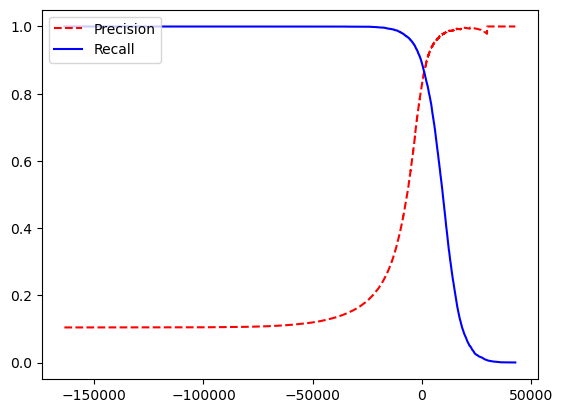

In [11]:
from sklearn.metrics import precision_recall_curve

y_scores = cross_val_predict(sgd_clf, X_train, y_train_7, cv=3, method="decision_function")
precisions, recalls, thresholds = precision_recall_curve(y_train_7, y_scores)

def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.plot(thresholds, precisions[:-1], "r--", label="Precision")
    plt.plot(thresholds, recalls[:-1], "b-", label="Recall")
    #plt.vlines(threshold, 0, 1.0, "k", "dotted", label="threshold")
    plt.legend(loc="upper left")

plot_precision_recall_vs_threshold(precisions, recalls, thresholds)
plt.show()

b)	Draw a diagram like the figure 3-5 in the course book. (1 point)

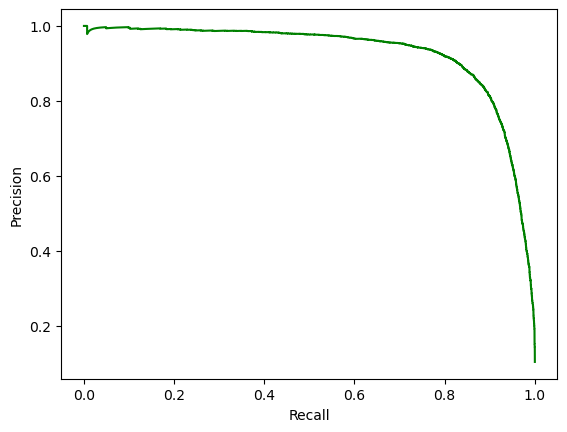

In [12]:
precisions, recalls, thresholds = precision_recall_curve(y_train_7, y_scores)

def plot_precision_vs_recall(precisions, recalls):
    plt.plot(recalls[:-1], precisions[:-1], "g-")
    plt.xlabel("Recall")
    plt.ylabel("Precision")

plot_precision_vs_recall(precisions, recalls)
plt.show()

 Then draw the ROC-curve and explain AUC.

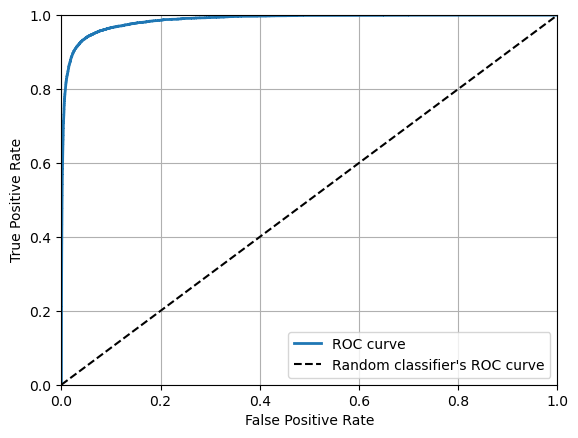

In [23]:
#Compute the TPR and FPR for various threshold values

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_train_7, y_scores)

def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label = "ROC curve")
    plt.plot([0,1],[0,1], 'k--' ,label="Random classifier's ROC curve")
    plt.axis([0,1,0,1])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()
    plt.grid(True)

plot_roc_curve(fpr, tpr)
plt.show()

In [17]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train_7, y_scores)
#

0.986670497551944

AUC = area under the curve.
A perfect classifier will have a ROC AUC score = 1 and purely random classifier will have 0.5.
You should prefer the PR curve whenever the positive class is rare or when you care more about the false positives than
the false negatives. Otherwise, use the ROC curve. 

In [28]:
#
from sklearn.svm import SVC

svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])
svm_clf.predict([some_digit])

array(['7'], dtype=object)

Since there are 10 classes, more than 2, Scikit-Learn used the OvO strategy and it trained 45 binary classifiers. Code actually made 45 predictions—one per pair of classes—and it selected the class that won the most duels.

In [30]:
some_digit_scores = svm_clf.decision_function([some_digit])
some_digit_scores.round(2)

array([[-0.29,  0.72,  8.29,  4.86,  6.27,  1.73,  2.76,  9.3 ,  3.78,
         7.26]])

In [31]:
#Highest score is on 7 (9,3)

7)	If you were developing a machine learning model to find fraudulent credit card transactions, which measure would you give more importance: Precision or Recall?

False Positive is more important in this case. Is better to catch safe actions and think those are fraudulent and study that case than let go false negatives. So it's better to have a higher recall and lower precision.